In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import reuters
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
num_words = 10000   # TODO (Q1a): 10000
maxlen=200     # TODO (Q1a): 200

(X_train, y_train), (X_test, y_test) = reuters.load_data(num_words=num_words, test_split=0.2)

# Q1b) pad both sets
X_train = pad_sequences(X_train, maxlen=maxlen)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=maxlen)   # TODO (Q1b): maxlen

# Q1c) how many topic classes? (labels are integers 0..45)
num_classes = int(max(y_train)) + 1  # TODO (Q1c): int(max(y_train)) + 1
print("X_train:", X_train.shape, " classes:", num_classes)

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (8982, 200)  classes: 46


In [3]:
assert X_train.shape[1] == 200, "pad reviews to length 200"
assert num_classes == 46, "Reuters has 46 topic classes"
print("Task 1 looks correct ✔")

Task 1 looks correct ✔


In [8]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM -> one summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

model.add(Dropout(0.5))

# Q2c) Output: one neuron PER CLASS with softmax
model.add(Dense(num_classes, activation='softmax'))   # TODO (Q2c): num_classes, 'softmax'

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 46)             │         5,934 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,384,750 (5.28 MB)

 Trainable params: 1,384,750 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Q3a) compile for integer multi-class labels
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',              # TODO (Q3a): 'sparse_categorical_crossentropy'
              metrics=['accuracy'])

# Q3b) train with a validation split
history = model.fit(X_train, y_train,
                    validation_split=0.2,   # TODO (Q3b): 0.2
                    epochs=10,             # TODO (Q3b): 10
                    batch_size=64)         # TODO (Q3b): 64

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 36s 297ms/step - accuracy: 0.4430 - loss: 2.3509 - val_accuracy: 0.5109 - val_loss: 1.9544
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 42s 307ms/step - accuracy: 0.5531 - loss: 1.8351 - val_accuracy: 0.5186 - val_loss: 2.2399
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 35s 312ms/step - accuracy: 0.5943 - loss: 1.6460 - val_accuracy: 0.5771 - val_loss: 1.6510
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 34s 299ms/step - accuracy: 0.6335 - loss: 1.4903 - val_accuracy: 0.6277 - val_loss: 1.5259
Epoch 5/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 42s 305ms/step - accuracy: 0.6754 - loss: 1.3036 - val_accuracy: 0.6227 - val_loss: 1.4940
Epoch 6/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 39s 290ms/step - accuracy: 0.7221 - loss: 1.1309 - val_accuracy: 0.6405 - val_loss: 1.4409
Epoch 7/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 33s 291ms/step - accuracy: 0.7577 - loss: 0.9787 - val_accuracy: 0.6656 - val_loss: 1.4349
Epoch 8/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 33s 296ms/step - accuracy: 0.7857 - loss: 0

71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.6505 - loss: 1.6415
Test accuracy: 65.05%


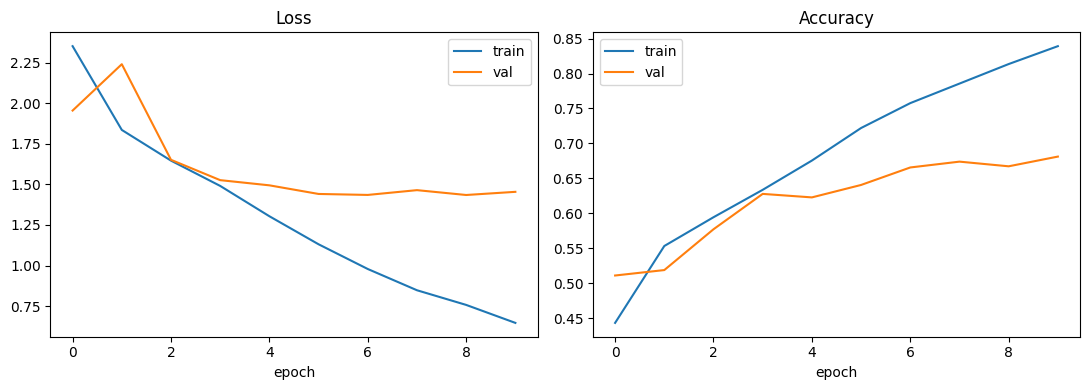

In [11]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 65-72%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

In [12]:
probs = model.predict(X_test[:5], verbose=0)   # shape (5, 46)

# Q5) pick the most likely topic for each review
pred_classes = np.argmax(probs, axis=1)
   # TODO (Q5): np.argmax(probs, axis=1)

for i in range(5):
    print(f"true topic: {y_test[i]:2d}   predicted: {pred_classes[i]:2d}")

true topic:  3   predicted:  3
true topic: 10   predicted: 24
true topic:  1   predicted: 19
true topic:  4   predicted: 16
true topic:  4   predicted: 13


### Task 6 — Short Answers

1. **Three differences between this model and Example A (IMDB):**
   - **Output units:** 46 units here (one for each topic class) vs 1 unit in Example A.
   - **Activation function:** `softmax` here (for multi-class probabilities) vs `sigmoid` in Example A (for binary class probability).
   - **Loss function:** `sparse_categorical_crossentropy` here (for integer labels) vs `binary_crossentropy` in Example A.

2. **Why `sparse_categorical_crossentropy` instead of `categorical_crossentropy`?**
   - Because our target labels (`y_train`, `y_test`) are formatted as integers ($0$ to $45$), rather than one-hot encoded vectors.

3. **What does identical Embedding and Bidirectional LSTM layers tell us about reusing sequence backbones?**
   - It tells us that standard sequential architectures are versatile backbones that can extract generic text/sequence representations regardless of whether the downstream task is binary classification, multi-class classification, or regression.

4. **Why 46-way classification is harder than 2-way classification:**
   - In 2-way (binary) classification, a random guess has a 50% baseline accuracy, and the model only needs to separate two broad concepts. In 46-way classification, the random baseline is only ~2.17%, and many of the 46 fine-grained topics have overlapping vocabularies, making it much harder to distinguish between closely related categories.